# Screen observability: whitelist and blacklist for RICO reconstruction

Some RICO screens are drawn by components that render outside the Android view system: a **WebView**, a video or OpenGL **surface**, a game **engine**, an **ad** container, a **map**. For those screens the cleaned view hierarchy (`utils.clean_screen`, the reconstruction target) holds one opaque box where the screenshot holds a whole page. The encoder still sees the page in the screenshot, so the embedding may carry content the JSON target cannot express. Such screens are a poor reconstruction target and a questionable training signal.

This notebook runs `screen_observability.py` over all 66,261 layouts and decides, per screen, whether it goes on the **whitelist** or the **blacklist**:

- **opaque subtree** — a cleaned component of an opaque class whose entire subtree carries no `text` and no `content-desc`. A WebView whose page content the accessibility layer exposed (children with text) is *not* opaque; an ad container wrapped in obfuscated framework views (children, but nothing readable) *is*.
- **opaque coverage** — union area of all opaque subtrees as a fraction of the device frame, computed on the cleaner's 1–100 grid.
- **blacklist** if the cleaned screen is empty, or opaque coverage ≥ `THRESHOLD` (0.5). **Whitelist** otherwise.

The class families were checked against a census of every class name in the corpus (the most frequent members are listed in the module). The continuous coverage stays in the output, so the threshold can be revisited without rescanning, and a sensitivity table below shows how the list sizes move with it.

Results are written to `screen_observability.csv` (+ `.meta.json`) next to `trace_layout_index.csv`, and the tables and figures to `graphics/screen_observability/`. Global RICO layout ids are used throughout; trace-local keys are resolved only through `trace_layout_index.csv`.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from PIL import Image

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository or a subdirectory.")
sys.path.insert(0, str(ROOT))
import utils
import screen_observability as so

LAYOUTS_DIR = ROOT.parent / "rico-data/data/layouts"
METADATA_PATH = ROOT.parent / "rico-data/data/play_store_metadata/app_details.csv"
TRACE_INDEX = ROOT / "trace_layout_index.csv"
SCAN_CSV = ROOT / "screen_observability.csv"
OUTPUT_DIR = ROOT / "graphics/screen_observability"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.5                                  # agreed cut on opaque coverage
SENSITIVITY = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
MIN_CLASS_SCREENS = 5                            # a class in fewer screens counts as rare
FORCE_RESCAN = False
RANDOM_STATE = 42
FAMILY_LABELS = {"webview": "WebView", "surface": "Surface / video", "engine": "Game engine",
                 "ad": "Ad container", "map": "Map"}

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "pdf.fonttype": 42, "ps.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)


def save_fig(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / f"{name}.png", bbox_inches="tight")


def pct(n, d):
    return 100.0 * n / d if d else float("nan")

## 1. Scan (or reuse the cached scan)

The scan is reused when its metadata still matches: same number of layouts, same `utils.py` and `screen_observability.py` hashes, same threshold and rare-class cut. Anything else triggers a rescan (a few minutes on CPU).

In [2]:
meta_path = SCAN_CSV.with_suffix(".meta.json")


def cache_is_current():
    if FORCE_RESCAN or not SCAN_CSV.is_file() or not meta_path.is_file():
        return False
    try:
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError):
        return False
    n_layouts = len(so.layout_paths(LAYOUTS_DIR)) if LAYOUTS_DIR.is_dir() else meta.get("screens")
    return (
        meta.get("screens") == n_layouts
        and meta.get("threshold") == THRESHOLD
        and meta.get("min_class_screens") == MIN_CLASS_SCREENS
        and meta.get("utils_sha256") == so._sha256(ROOT / "utils.py")
        and meta.get("module_sha256") == so._sha256(ROOT / "screen_observability.py")
    )


if cache_is_current():
    screens = so.load_scan(SCAN_CSV)
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    print(f"Loaded cached scan: {len(screens):,} screens from {SCAN_CSV.name} "
          f"(generated {meta['generated_utc']}, {meta['elapsed_seconds']} s)")
else:
    from tqdm.auto import tqdm
    if not LAYOUTS_DIR.is_dir():
        raise FileNotFoundError(f"RICO layouts not found at {LAYOUTS_DIR}")
    screens, meta = so.run_scan(
        layouts_dir=LAYOUTS_DIR, threshold=THRESHOLD, min_class_screens=MIN_CLASS_SCREENS,
        progress=lambda it, total: tqdm(it, total=total, desc="Scanning screens"),
    )
    so.write_outputs(screens, meta, SCAN_CSV)
    print(f"Scanned {len(screens):,} screens in {meta['elapsed_seconds']} s -> {SCAN_CSV.name}")

N_SCREENS = len(screens)
screens["list"] = pd.Categorical(screens["list"], categories=["whitelist", "blacklist"])
print(f"whitelist {meta['whitelist']:,} | blacklist {meta['blacklist']:,} "
      f"(empty {meta['blacklist_empty']:,}, opaque {meta['blacklist_opaque']:,}) at threshold {meta['threshold']}")
print(f"distinct cleaned classes in corpus: {meta['distinct_classes_in_corpus']:,}; "
      f"rare (< {MIN_CLASS_SCREENS} screens): {meta['rare_classes_in_corpus']:,}")
display(screens.head())

Loaded cached scan: 66,261 screens from screen_observability.csv (generated 2026-09-09T22:25:11+00:00, 22.4 s)
whitelist 55,220 | blacklist 11,041 (empty 169, opaque 10,872) at threshold 0.5
distinct cleaned classes in corpus: 28,047; rare (< 5 screens): 21,370


,app,activity,raw_node_count,raw_opaque_nodes,raw_opaque_visible_nodes,clean_component_count,clean_leaf_count,text_component_count,max_depth,opaque_coverage,opaque_subtree_count,opaque_exempt_count,largest_opaque_fraction,largest_opaque_class,leaf_coverage,largest_component_fraction,largest_image_leaf_fraction,cov_ad,cov_map,cov_engine,cov_webview,cov_surface,clean_distinct_classes,rare_class_share,reason,list
screen_id,,,,,,,,,,,,,,,,,,,,,,,,,,
0,com.brc.PeriodTrackerDiary,MainActivity,21,11,1,1,0,0,1,0.929293,1,0,0.929293,org.apache.cordova.engine.SystemWebView,0.000000,0.929293,0.000000,0.000000,0.0,0.0,0.929293,0.000000,1,0.000000,opaque,blacklist
1,com.brc.PeriodTrackerDiary,MainActivity,21,11,7,8,1,0,1,0.919192,2,0,0.858586,org.apache.cordova.engine.SystemWebView,0.000000,0.858586,0.000000,0.060606,0.0,0.0,0.858586,0.000000,7,0.000000,opaque,blacklist
2,se.perigee.android.seven,ActivitySettingsGoggleFit,35,0,0,10,6,5,5,0.000000,0,0,0.000000,NaN,0.528926,0.581063,0.000000,0.000000,0.0,0.0,0.000000,0.000000,8,0.000000,,whitelist
3,se.perigee.android.seven,WorkoutSessionActivity,75,3,1,10,6,5,3,0.565657,1,0,0.565657,com.perigee.seven.ui.view.VideoView,0.188450,0.828283,0.000000,0.000000,0.0,0.0,0.000000,0.565657,8,0.300000,opaque,blacklist
4,se.perigee.android.seven,WorkoutSessionCompleteActivity,70,0,0,29,20,14,4,0.000000,0,0,0.000000,NaN,0.391287,0.274258,0.003571,0.000000,0.0,0.0,0.000000,0.000000,10,0.068965,,whitelist


## 2. Opaque coverage distribution and threshold sensitivity

The histogram is on a log count axis because most screens have zero coverage. Dashed lines mark 0.3, 0.5 and 0.7. The table reports the blacklist size at every candidate threshold; the empty-screen rule contributes the same 169 screens at every threshold.

screens with any opaque coverage : 22,943 (34.63 %)
quantiles of coverage among those :


,0.10,0.25,0.50,0.75,0.90,0.95
coverage,0.056,0.061,0.323,0.899,0.97,1.0


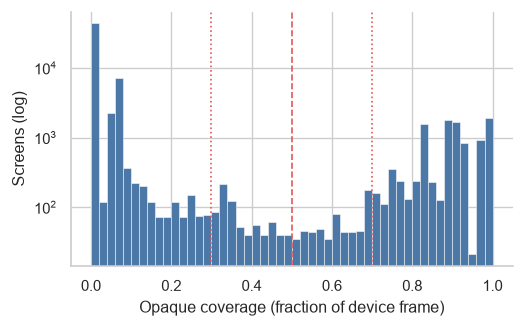

threshold,blacklist,blacklist_pct,of_which_opaque,whitelist
0.1,12973,19.58,12804,53288
0.2,12288,18.54,12119,53973
0.3,11792,17.80,11623,54469
0.4,11279,17.02,11110,54982
0.5,11041,16.66,10872,55220
0.6,10834,16.35,10665,55427
0.7,10440,15.76,10271,55821
0.8,9444,14.25,9275,56817
0.9,5506,8.31,5337,60755


In [3]:
cov = screens["opaque_coverage"]
print(f"screens with any opaque coverage : {int((cov > 0).sum()):,} ({pct((cov > 0).sum(), N_SCREENS):.2f} %)")
print("quantiles of coverage among those :")
display(cov[cov > 0].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).rename("coverage").to_frame().T.round(3))

fig, ax = plt.subplots(figsize=(4.75, 2.75))
ax.hist(cov, bins=50, range=(0, 1), color="#4C78A8", edgecolor="white", linewidth=0.3)
ax.set_yscale("log")
for t, ls in ((0.3, ":"), (THRESHOLD, "--"), (0.7, ":")):
    ax.axvline(t, color="#E45756", linestyle=ls, linewidth=1)
ax.set(xlabel="Opaque coverage (fraction of device frame)", ylabel="Screens (log)")
save_fig(fig, "opaque_coverage_hist")
plt.show()

empty = screens["clean_component_count"].eq(0)
rows = []
for t in SENSITIVITY:
    black = empty | cov.ge(t)
    rows.append({"threshold": t, "blacklist": int(black.sum()), "blacklist_pct": pct(black.sum(), N_SCREENS),
                 "of_which_opaque": int((cov.ge(t) & ~empty).sum()), "whitelist": int((~black).sum())})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv(OUTPUT_DIR / "threshold_sensitivity.csv", index=False)
display(sensitivity.style.format({"threshold": "{:.1f}", "blacklist_pct": "{:.2f}"}).hide(axis="index"))

## 3. The lists at the chosen threshold

Which family of opaque component is responsible, and which concrete classes dominate the blacklist. A screen can carry several families; the family table counts screens where that family alone reaches the threshold as well as screens where it is present at all.

In [4]:
lists = (screens.groupby(["list", "reason"], observed=True).size().rename("screens").reset_index())
lists["pct"] = lists["screens"].map(lambda n: pct(n, N_SCREENS))
lists.to_csv(OUTPUT_DIR / "list_sizes.csv", index=False)
display(lists.style.format({"pct": "{:.2f}"}).hide(axis="index"))

fam_rows = []
for fam in so.FAMILY_ORDER:
    c = screens[f"cov_{fam}"]
    fam_rows.append({
        "family": FAMILY_LABELS[fam],
        "screens_present": int((c > 0).sum()),
        "present_pct": pct((c > 0).sum(), N_SCREENS),
        "mean_cov_when_present": c[c > 0].mean(),
        "median_cov_when_present": c[c > 0].median(),
        f"screens_at_or_above_{THRESHOLD}": int(c.ge(THRESHOLD).sum()),
    })
families = pd.DataFrame(fam_rows)
families.to_csv(OUTPUT_DIR / "family_prevalence.csv", index=False)
display(families.style.format({"present_pct": "{:.2f}", "mean_cov_when_present": "{:.3f}",
                               "median_cov_when_present": "{:.3f}"}).hide(axis="index"))

black = screens[screens["list"].eq("blacklist")]
top_classes = (black[black["reason"].eq("opaque")]["largest_opaque_class"].value_counts()
               .rename("blacklisted_screens").reset_index().rename(columns={"index": "class"}))
top_classes["family"] = top_classes["largest_opaque_class"].map(lambda c: FAMILY_LABELS[so.family_of(c)])
top_classes.to_csv(OUTPUT_DIR / "blacklist_top_classes.csv", index=False)
print("Largest opaque component on blacklisted screens (top 25 classes):")
display(top_classes.head(25).style.hide(axis="index"))

list,reason,screens,pct
whitelist,,55220,83.34
blacklist,empty,169,0.26
blacklist,opaque,10872,16.41


family,screens_present,present_pct,mean_cov_when_present,median_cov_when_present,screens_at_or_above_0.5
Ad container,14401,21.73,0.172,0.061,1600
Map,1783,2.69,0.727,0.828,1523
Game engine,273,0.41,0.973,1.000,268
WebView,6904,10.42,0.783,0.879,6076
Surface / video,1834,2.77,0.758,0.909,1410


Largest opaque component on blacklisted screens (top 25 classes):


largest_opaque_class,blacklisted_screens,family
android.webkit.WebView,3003,WebView
com.android.browser.BrowserWebView,1125,WebView
com.google.maps.api.android.lib6.impl.fr,952,Map
com.facebook.webview.BasicWebView,695,WebView
com.google.android.gms.ads.internal.overlay.q,528,Ad container
com.google.android.gms.ads.internal.webview.n,516,Ad container
android.view.SurfaceView,318,Surface / video
android.view.TextureView,315,Surface / video
maps.ad.ay$a,301,Map
org.apache.cordova.engine.SystemWebView,244,WebView


## 4. Raw versus cleaned view of opaque components

The raw hierarchy contains many opaque nodes that the cleaner already discards (invisible or zero-area), and some WebViews expose their page content as labelled children and are therefore exempt. This is why a class-presence rule on the raw JSON would over-blacklist.

In [5]:
raw_any = screens["raw_opaque_nodes"].gt(0)
clean_any = screens["opaque_subtree_count"].gt(0)
exempt_any = screens["opaque_exempt_count"].gt(0)
raw_vs_clean = pd.DataFrame({
    "screens": [raw_any.sum(), screens["raw_opaque_visible_nodes"].gt(0).sum(), clean_any.sum(),
                exempt_any.sum(), (raw_any & ~clean_any & ~exempt_any).sum(), screens["list"].eq("blacklist").sum()],
}, index=["raw hierarchy has an opaque-class node",
          "... of which visible with positive area",
          "cleaned tree has an opaque subtree (no text below)",
          "cleaned tree has an opaque-class node exempted because its subtree carries text",
          "raw opaque node dropped entirely by cleaning",
          "blacklisted"]).astype(int)
raw_vs_clean["pct"] = raw_vs_clean["screens"].map(lambda n: pct(n, N_SCREENS))
raw_vs_clean.to_csv(OUTPUT_DIR / "raw_vs_clean_opaque.csv")
display(raw_vs_clean.style.format({"pct": "{:.2f}"}))

,screens,pct
raw hierarchy has an opaque-class node,27880,42.08
... of which visible with positive area,23558,35.55
cleaned tree has an opaque subtree (no text below),22993,34.70
cleaned tree has an opaque-class node exempted because its subtree carries text,3454,5.21
raw opaque node dropped entirely by cleaning,4369,6.59
blacklisted,11041,16.66


## 5. What else differs between the lists

Blacklisted screens are short: few components, little text. That matters for the later comparison, because string and positional metrics reward short targets. These covariates (component count, text components, rare-class share) are the controls for the analysis of the existing reconstruction runs, and `rare_class_share` is a difficulty of its own that must not be confused with opaqueness. Rare classes are counted on the **full class path** (which the decoder has to spell), so the corpus has more distinct classes here than the short-name count in `rico-metrics.ipynb`.

covariate,list,n,mean,sd,median,q1,q3,covariate_label
clean_component_count,whitelist,55220,25.102,20.082,20.000,11.000,34.000,Cleaned components
clean_component_count,blacklist,11041,12.012,14.561,7.000,4.000,14.000,Cleaned components
clean_leaf_count,whitelist,55220,18.726,15.363,14.000,8.000,25.000,Leaf components
clean_leaf_count,blacklist,11041,7.442,10.469,4.000,1.000,9.000,Leaf components
largest_image_leaf_fraction,whitelist,55220,0.032,0.136,0.000,0.000,0.001,Largest unlabelled image leaf
largest_image_leaf_fraction,blacklist,11041,0.010,0.081,0.000,0.000,0.000,Largest unlabelled image leaf
leaf_coverage,whitelist,55220,0.511,0.281,0.492,0.262,0.767,Leaf coverage of frame
leaf_coverage,blacklist,11041,0.230,0.348,0.048,0.000,0.269,Leaf coverage of frame
max_depth,whitelist,55220,2.934,1.405,3.000,2.000,4.000,Tree depth
max_depth,blacklist,11041,2.537,1.457,2.000,1.000,4.000,Tree depth


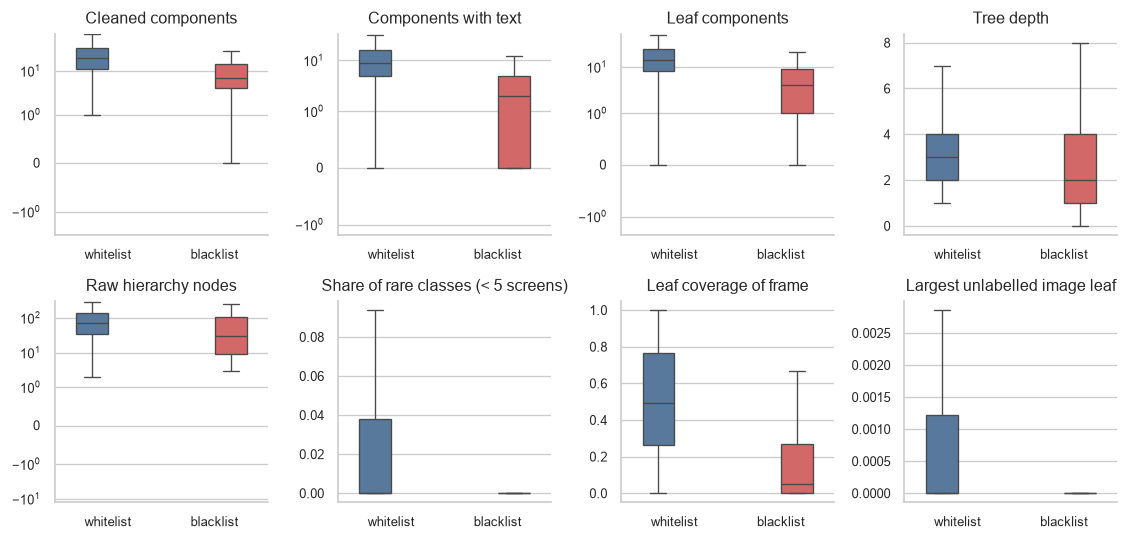

In [6]:
COVARIATES = {
    "clean_component_count": ("Cleaned components", True),
    "text_component_count": ("Components with text", True),
    "clean_leaf_count": ("Leaf components", True),
    "max_depth": ("Tree depth", False),
    "raw_node_count": ("Raw hierarchy nodes", True),
    "rare_class_share": (f"Share of rare classes (< {MIN_CLASS_SCREENS} screens)", False),
    "leaf_coverage": ("Leaf coverage of frame", False),
    "largest_image_leaf_fraction": ("Largest unlabelled image leaf", False),
}
cov_stats = (screens.melt(id_vars=["list"], value_vars=list(COVARIATES), var_name="covariate", value_name="value")
             .groupby(["covariate", "list"], observed=True)["value"]
             .agg(n="count", mean="mean", sd="std", median="median",
                  q1=lambda v: v.quantile(0.25), q3=lambda v: v.quantile(0.75)).reset_index())
cov_stats["covariate_label"] = cov_stats["covariate"].map(lambda c: COVARIATES[c][0])
cov_stats.to_csv(OUTPUT_DIR / "covariates_by_list.csv", index=False)
display(cov_stats.style.format({"mean": "{:.3f}", "sd": "{:.3f}", "median": "{:.3f}", "q1": "{:.3f}", "q3": "{:.3f}"})
        .hide(axis="index"))

fig, axes = plt.subplots(2, 4, figsize=(9.5, 4.6))
palette = {"whitelist": "#4C78A8", "blacklist": "#E45756"}
for ax, (col, (label, log)) in zip(axes.ravel(), COVARIATES.items()):
    sns.boxplot(data=screens, x="list", y=col, hue="list", palette=palette, legend=False,
                showfliers=False, width=0.6, linewidth=0.8, ax=ax)
    if log:
        ax.set_yscale("symlog", linthresh=1)
    ax.set(title=label, xlabel="", ylabel="")
    ax.tick_params(labelsize=8)
fig.tight_layout()
save_fig(fig, "covariates_by_list")
plt.show()

## 6. Apps and Play Store categories

Corruption is mostly an app property: a Cordova or Unity app is opaque on every screen. Apps are grouped by how many of their screens are blacklisted, and the blacklist share is broken down by Play Store category from `app_details.csv`. Categories with fewer than 200 screens are pooled into *Other*; apps that are missing from the metadata file (about 4,000 screens) are kept as their own group, because they turn out to be blacklisted far more often than average.

,apps,screens,blacklisted_screens,apps_pct
app_status,,,,
no screen blacklisted,4655,29184,0,50.10
partly blacklisted,3606,35492,9456,38.81
fully blacklisted,1030,1585,1585,11.09


Apps contributing the most blacklisted screens:


,screens,blacklisted,share,app_status
app,,,,
com.android.browser,1409,1127,0.80,partly blacklisted
com.facebook.katana,938,722,0.77,partly blacklisted
com.android.gallery3d,257,243,0.95,partly blacklisted
com.android.camera2,237,226,0.95,partly blacklisted
com.google.android.apps.maps,56,41,0.73,partly blacklisted
com.citymapper.app.release,39,28,0.72,partly blacklisted
com.opera.android.browser,27,26,0.96,partly blacklisted
com.nbcuni.nbcots.nbcwashington.android,31,24,0.77,partly blacklisted
ch.admin.meteoswiss,25,24,0.96,partly blacklisted


screens with a Play Store category: 62,272 of 66,261


,screens,blacklisted,blacklist_pct
category_group,,,
No Play Store metadata,3989,1635,40.99
Maps & Navigation,1815,498,27.44
Weather,2890,703,24.33
Social,4625,1121,24.24
Beauty,456,95,20.83
News & Magazines,3363,676,20.10
Books & Reference,3222,630,19.55
Entertainment,4762,904,18.98
House & Home,587,111,18.91


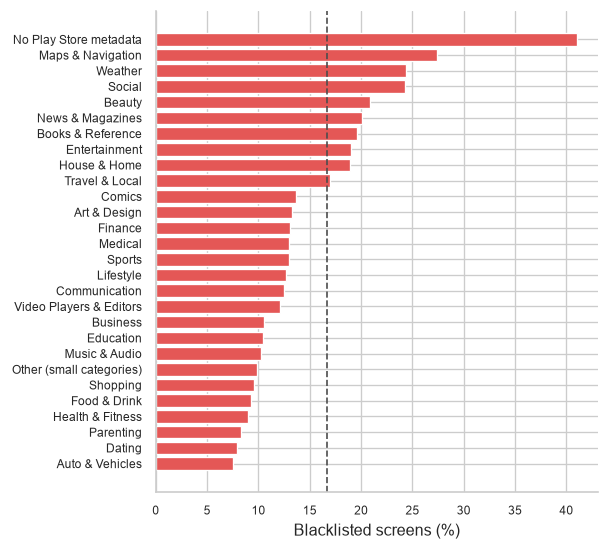

In [7]:
per_app = (screens.groupby("app").agg(screens=("list", "size"),
                                      blacklisted=("list", lambda s: int(s.eq("blacklist").sum())))
           .assign(share=lambda d: d["blacklisted"] / d["screens"]))
per_app["app_status"] = pd.cut(per_app["share"], bins=[-0.01, 0.0, 0.999, 1.0],
                               labels=["no screen blacklisted", "partly blacklisted", "fully blacklisted"])
app_status = per_app.groupby("app_status", observed=True).agg(apps=("share", "size"), screens=("screens", "sum"),
                                                              blacklisted_screens=("blacklisted", "sum"))
app_status["apps_pct"] = app_status["apps"].map(lambda n: pct(n, len(per_app)))
app_status.to_csv(OUTPUT_DIR / "app_status.csv")
display(app_status.style.format({"apps_pct": "{:.2f}"}))

print("Apps contributing the most blacklisted screens:")
display(per_app.sort_values("blacklisted", ascending=False).head(15).style.format({"share": "{:.2f}"}))

if METADATA_PATH.is_file():
    metadata = pd.read_csv(METADATA_PATH, usecols=["App Package Name", "Category"], dtype=str)
    metadata = metadata.dropna().drop_duplicates("App Package Name").set_index("App Package Name")["Category"]
    screens["category"] = screens["app"].map(metadata)
    cat_counts = screens["category"].value_counts()
    screens["category_group"] = np.select(
        [screens["category"].isna(), screens["category"].map(cat_counts).fillna(0).ge(200)],
        ["No Play Store metadata", screens["category"]], default="Other (small categories)")
    by_cat = (screens.groupby("category_group")
              .agg(screens=("list", "size"), blacklisted=("list", lambda s: int(s.eq("blacklist").sum())))
              .assign(blacklist_pct=lambda d: 100 * d["blacklisted"] / d["screens"])
              .sort_values("blacklist_pct", ascending=False))
    by_cat.to_csv(OUTPUT_DIR / "blacklist_share_by_category.csv")
    print(f"screens with a Play Store category: {screens['category'].notna().sum():,} of {N_SCREENS:,}")
    display(by_cat.style.format({"blacklist_pct": "{:.2f}"}))

    fig, ax = plt.subplots(figsize=(4.75, 5.2))
    order = by_cat.index.tolist()
    ax.barh(order, by_cat["blacklist_pct"], color="#E45756")
    ax.axvline(pct(screens["list"].eq("blacklist").sum(), N_SCREENS), color="0.3", linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.set(xlabel="Blacklisted screens (%)", ylabel="")
    ax.tick_params(labelsize=7)
    save_fig(fig, "blacklist_share_by_category")
    plt.show()
else:
    print(f"No Play Store metadata at {METADATA_PATH}; category breakdown skipped.")

## 7. Approximate membership in the adapter's train / validation split

`2_train_adapter.py` orders screens by id, drops targets longer than 4,096 tokens (about 290 screens) and takes the first 80 % for training. The exact split needs the tokenizer and is recovered in `_results_reconstructions_boxplots.ipynb`; here the id-ordered 80/20 cut **without** the token exclusion is used, which moves the boundary by at most a few hundred ids. The numbers say how many screens each training arm would have and how large a size-matched whitelist subsample must be.

In [8]:
ordered = screens.sort_index()
train_size = int(len(ordered) * 0.8)
ordered["split"] = np.where(np.arange(len(ordered)) < train_size, "train (approx.)", "validation (approx.)")
split_table = pd.crosstab(ordered["split"], ordered["list"], margins=True)
split_table.to_csv(OUTPUT_DIR / "split_by_list_approx.csv")
display(split_table)
black_train = int(((ordered["split"] == "train (approx.)") & ordered["list"].eq("blacklist")).sum())
print(f"blacklist-only training arm would see about {black_train:,} screens; "
      f"a size-matched whitelist arm needs a subsample of the same size.")

list,whitelist,blacklist,All
split,,,
train (approx.),44175,8833,53008
validation (approx.),11045,2208,13253
All,55220,11041,66261


blacklist-only training arm would see about 8,833 screens; a size-matched whitelist arm needs a subsample of the same size.


## 8. Examples

Top row: blacklisted screens, one per family where available, with the opaque subtrees outlined in red on the screenshot. Bottom row: borderline whitelisted screens with coverage between 0.3 and the threshold, i.e. the screens a lower threshold would move. Selection is deterministic (`RANDOM_STATE`). Note that a blacklisted screen can *look* native: an Adobe AIR or Unity app paints its own widgets into one surface, and the hierarchy holds a single component.

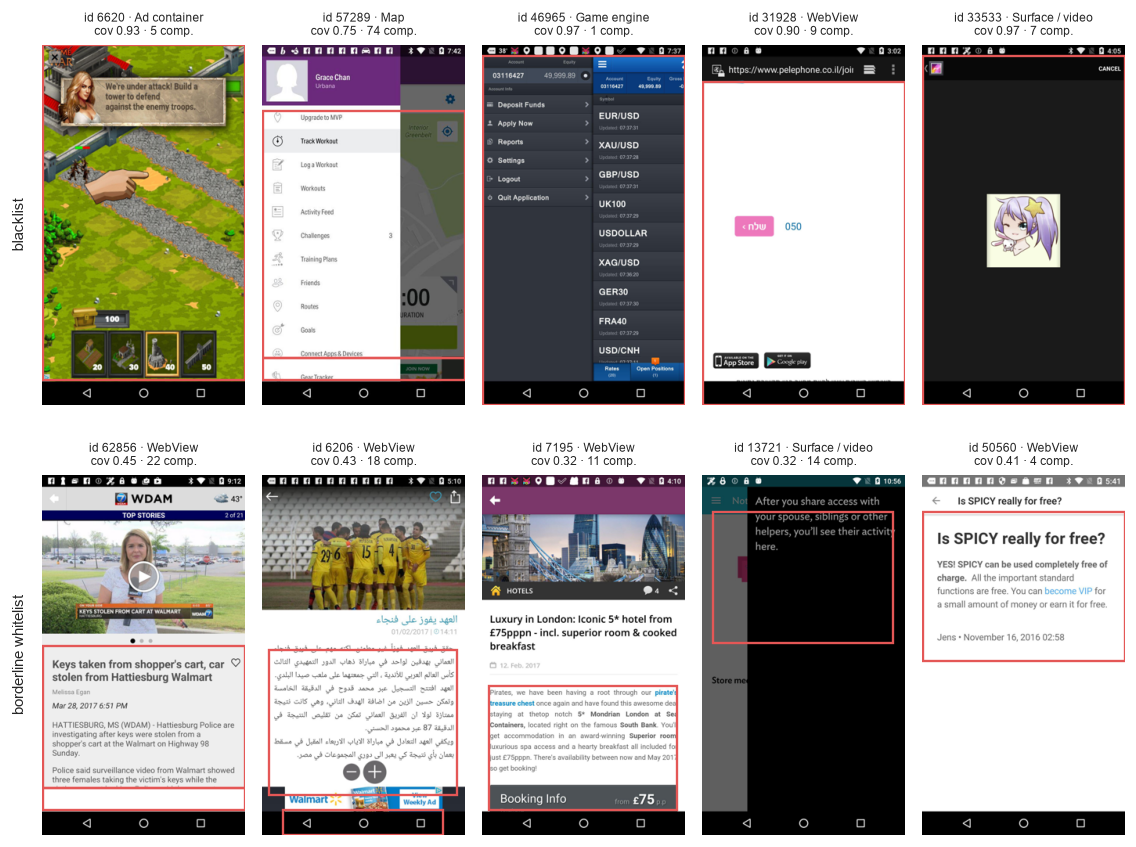

shown ids: [6620, 57289, 46965, 31928, 33533] [62856, 6206, 7195, 13721, 50560]


In [9]:
def opaque_boxes(screen_id):
    tree = utils.clean_screen(LAYOUTS_DIR / f"{screen_id}.json")
    boxes = []
    stack = list(tree["components"])
    while stack:
        node = stack.pop()
        if not isinstance(node, dict):
            continue
        if so.family_of(node.get("class")) is not None and not so.subtree_has_text(node):
            boxes.append(node["bounds"])
            continue
        stack.extend(node.get("children") or [])
    return boxes


def show_examples(ax, screen_id):
    row = screens.loc[screen_id]
    image = Image.open(LAYOUTS_DIR / f"{screen_id}.jpg").convert("RGB")
    image.thumbnail((260, 460))
    w, h = image.size
    ax.imshow(image)
    for x1, y1, x2, y2 in opaque_boxes(screen_id):
        ax.add_patch(plt.Rectangle(((x1 - 1) / 99 * w, (y1 - 1) / 99 * h), (x2 - x1) / 99 * w, (y2 - y1) / 99 * h,
                                   fill=False, edgecolor="#E45756", linewidth=1.4))
    fam = so.family_of(row["largest_opaque_class"]) if isinstance(row["largest_opaque_class"], str) else None
    ax.set_title(f"id {screen_id} · {FAMILY_LABELS.get(fam, '–')}\ncov {row['opaque_coverage']:.2f} · "
                 f"{int(row['clean_component_count'])} comp.", fontsize=7)
    ax.set_axis_off()


rng = np.random.default_rng(RANDOM_STATE)
opaque_black = screens[screens["reason"].eq("opaque")]
top_ids = []
for fam in so.FAMILY_ORDER:
    pool = opaque_black[opaque_black["largest_opaque_class"].map(lambda c: so.family_of(c) == fam, na_action="ignore").fillna(False).astype(bool)]
    if len(pool):
        top_ids.append(int(rng.choice(pool.index)))
borderline = screens[screens["list"].eq("whitelist") & screens["opaque_coverage"].between(0.3, THRESHOLD, inclusive="left")]
bottom_ids = [int(i) for i in rng.choice(borderline.index, size=min(5, len(borderline)), replace=False)]

fig, axes = plt.subplots(2, 5, figsize=(9.5, 7.5))
for ax in axes.ravel():
    ax.set_axis_off()
for ax, sid in zip(axes[0], top_ids):
    show_examples(ax, sid)
for ax, sid in zip(axes[1], bottom_ids):
    show_examples(ax, sid)
axes[0, 0].text(-0.15, 0.5, "blacklist", transform=axes[0, 0].transAxes, rotation=90, va="center", fontsize=9)
axes[1, 0].text(-0.15, 0.5, "borderline whitelist", transform=axes[1, 0].transAxes, rotation=90, va="center", fontsize=9)
fig.tight_layout()
save_fig(fig, "examples")
plt.show()
print("shown ids:", top_ids, bottom_ids)

## 9. Traces

Although the experiment is screen-level, the trace view shows how the lists would carry over to the sequence task: a trace is counted as *mixed* when it contains both whitelisted and blacklisted screens. Trace keys are resolved through `trace_layout_index.csv`.

In [10]:
if TRACE_INDEX.is_file():
    tidx = pd.read_csv(TRACE_INDEX)
    tidx["list"] = tidx["layout_id"].map(screens["list"].astype(str))
    per_trace = (tidx.groupby(["app", "trace"]).agg(screens=("layout_id", "size"),
                                                    blacklisted=("list", lambda s: int(s.eq("blacklist").sum())))
                 .assign(share=lambda d: d["blacklisted"] / d["screens"]))
    per_trace["trace_status"] = pd.cut(per_trace["share"], bins=[-0.01, 0.0, 0.999, 1.0],
                                       labels=["all whitelist", "mixed", "all blacklist"])
    trace_status = per_trace.groupby("trace_status", observed=True).agg(traces=("share", "size"), screens=("screens", "sum"))
    trace_status["traces_pct"] = trace_status["traces"].map(lambda n: pct(n, len(per_trace)))
    per_trace.to_csv(OUTPUT_DIR / "trace_blacklist_share.csv")
    trace_status.to_csv(OUTPUT_DIR / "trace_status.csv")
    display(trace_status.style.format({"traces_pct": "{:.2f}"}))
    mixed = per_trace[per_trace["trace_status"].eq("mixed")]
    print(f"mixed traces: {len(mixed):,}; median blacklisted share within them {mixed['share'].median():.2f}")
else:
    print(f"{TRACE_INDEX.name} missing; run 0_build_trace_index.py first.")

,traces,screens,traces_pct
trace_status,,,
all whitelist,4560,22997,44.38
mixed,4688,41517,45.62
all blacklist,1028,1643,10.00


mixed traces: 4,688; median blacklisted share within them 0.25


## 10. Export

Id lists for the training arms, one global RICO id per line, plus a summary of everything above.

In [11]:
white_ids = screens.index[screens["list"].eq("whitelist")].to_series().sort_values()
black_ids = screens.index[screens["list"].eq("blacklist")].to_series().sort_values()
(OUTPUT_DIR / "whitelist_ids.txt").write_text("\n".join(map(str, white_ids)) + "\n", encoding="utf-8")
(OUTPUT_DIR / "blacklist_ids.txt").write_text("\n".join(map(str, black_ids)) + "\n", encoding="utf-8")

summary = {
    "threshold": THRESHOLD,
    "screens": int(N_SCREENS),
    "whitelist": int(len(white_ids)),
    "blacklist": int(len(black_ids)),
    "blacklist_empty": int(screens["reason"].eq("empty").sum()),
    "blacklist_opaque": int(screens["reason"].eq("opaque").sum()),
    "screens_with_any_opaque_coverage": int((screens["opaque_coverage"] > 0).sum()),
    "apps": int(screens["app"].nunique()),
    "apps_fully_blacklisted": int(per_app["app_status"].eq("fully blacklisted").sum()),
    "apps_partly_blacklisted": int(per_app["app_status"].eq("partly blacklisted").sum()),
    "scan_meta": meta,
}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps({k: v for k, v in summary.items() if k != "scan_meta"}, indent=2))
print("\nfiles in", OUTPUT_DIR.relative_to(ROOT))
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {path.name:45s} {path.stat().st_size / 1024:8.1f} KB")

{
  "threshold": 0.5,
  "screens": 66261,
  "whitelist": 55220,
  "blacklist": 11041,
  "blacklist_empty": 169,
  "blacklist_opaque": 10872,
  "screens_with_any_opaque_coverage": 22943,
  "apps": 9291,
  "apps_fully_blacklisted": 1030,
  "apps_partly_blacklisted": 3606
}

files in graphics/screen_observability
  app_status.csv                                     0.2 KB
  blacklist_ids.txt                                 62.9 KB
  blacklist_share_by_category.csv                    1.1 KB
  blacklist_share_by_category.pdf                   27.7 KB
  blacklist_share_by_category.png                   55.7 KB
  blacklist_top_classes.csv                         34.3 KB
  covariates_by_list.csv                             1.8 KB
  covariates_by_list.pdf                            25.7 KB
  covariates_by_list.png                            64.2 KB
  examples.pdf                                     721.7 KB
  examples.png                                     798.4 KB
  family_prevalence.csv     